# Apply Optical Perturbations

This notebook demonstrates how to apply optical perturbations using physics-based sensor models via pyBSM. Optical perturbations simulate the effects of different sensor configurations (focal length, aperture diameter, pixel pitch) and scenario parameters (e.g. altitude, ground range, visibility) on image formation using Optical Transfer Function (OTF) modeling.

OTFs mathematically describe how an optical system transfers spatial frequency information from a scene to the captured image. By perturbing different OTF components, we can simulate various physical phenomena such as diffraction, defocus, detector integration, motion blur (jitter), and atmospheric turbulence.

Each OTF covered here includes a detailed summary, a test input image, and the perturbed result image, along with a code sample.

```{seealso}
For foundational theory on image formation concepts and OTFs, see the [pyBSM explanation](https://pybsm.readthedocs.io/en/stable/explanation.html).
```

To run this notebook in Colab, use the link below:

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kitware/nrtk/blob/main/docs/examples/optical_perturbers.ipynb)

## Set Up the Environment

```{note}
We are suppressing warnings within this notebook to reduce visual clutter for demonstration purposes. If any issues arise while executing this notebook, we recommend that this cell is **not** executed so that any related warnings are shown.
```

In [1]:
import warnings

warnings.filterwarnings("ignore")

```{important}
This notebook requires NRTK with the following extra(s):

- `pybsm`: pyBSM sensor simulation library for physics-based optical transfer function perturbations

The next cell will install these extra(s). See [Installation](<project:/getting_started/installation.rst>) for alternatives.
```

In [2]:
%pip install -qU pip
print("Installing nrtk with required extras...")
%pip install -q "nrtk[pybsm,headless]"
print("Done!")

from nrtk.utils._extras import print_extras_status  # noqa: E402 - intentionally after %pip install

print_extras_status()

Note: you may need to restart the kernel to use updated packages.
Installing nrtk with required extras...


Note: you may need to restart the kernel to use updated packages.
Done!


Detected status of NRTK extras and their dependencies:



[albumentations]
  - nrtk-albumentations       ✗ missing

[diffusion]
  - torch                     ✗ missing
  - diffusers                 ✗ missing
  - accelerate                ✗ missing
  - Pillow                    ✓ 12.3.0
  - transformers              ✗ missing
  - protobuf                  ✗ missing

[graphics]
  - opencv-python             ✗ missing

[hcipy]
  - hcipy                     ✗ missing
  - scipy                     ✓ 1.18.1
  - xxhash                    ✗ missing

[headless]
  - opencv-python-headless    ✓ 5.0.0.93

[maite]
  - maite                     ✗ missing

[pillow]
  - Pillow                    ✓ 12.3.0

[pyav]
  - av                        ✓ 17.1.0

[pybsm]
  - pybsm                     ✓ 0.16.0

[skimage]
  - scikit-image              ✗ missing

[tools]
  - kwcoco                    ✗ missing
  - Pillow                    ✓ 12.3.0
  - click                     ✓ 8.5.0
  - fastapi                   ✗ missing
  - uvicorn                   ✗ missing
  - pyda

    https://nrtk.readthedocs.io/en/stable/



```{note}
**Colab users**: After setting up the environment, you may need to "Restart Runtime" to resolve package version conflicts (see the [README](https://github.com/Kitware/nrtk/blob/main/docs/examples/README.md#run-the-notebooks-from-colab) for more info).
```

We'll use a sample military vehicle image to demonstrate optical perturbations. This image represents the scene before any optical system effects are applied.

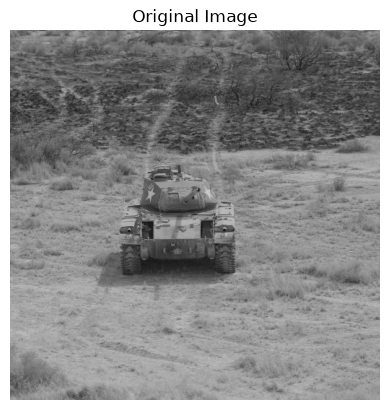

In [3]:
import os
import urllib.request

import cv2
import matplotlib.pyplot as plt
import numpy as np

data_dir = "./data"
os.makedirs(data_dir, exist_ok=True)

url = "https://data.kitware.com/api/v1/item/6596fde89c30d6f4e17c9efc/download"

image_path = os.path.join(data_dir, "M-41 Walker Bulldog (USA) width 319cm height 272cm.tiff")
if not os.path.isfile(image_path):
    _ = urllib.request.urlretrieve(url, image_path)


image = np.asarray(cv2.imread(image_path))
img_gsd = 3.19 / 160.0

fig, ax = plt.subplots()
ax.imshow(image)  # type: ignore
ax.set_title("Original Image")
ax.set_axis_off()  # type: ignore

We will also define a helper function for displaying the original and augmented images side by side.

In [4]:
def display_augmented_image(original_image: np.ndarray, augmented_image: np.ndarray, augmented_title: str) -> None:
    """Helper function to display the original image and augmented image."""
    _, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(original_image)  # type: ignore
    ax[0].set_title("Original Image")
    ax[0].set_axis_off()  # type: ignore
    ax[1].imshow(augmented_image)  # type: ignore
    ax[1].set_title(augmented_title)
    ax[1].set_axis_off()  # type: ignore

## Circular Aperture Perturbation

The Circular Aperture OTF encompasses the diffraction effects from the circular aperture model. This is an
approximation for changes to the model such as changing the lens of the sensor.

Multispectral imaging captures light across several wavelength bands, typically ranging from the visible to the
infrared spectrum. These bands can be broadly categorized as visible, near-infrared (NIR), short-wave infrared
(SWIR), mid-wave infrared (MWIR), and long-wave infrared (LWIR). Each band provides unique information about
the scene, and the weights assigned to each band can be adjusted to optimize for specific applications.
The spectral weights determine the relative spectral contributions to the signal collected by a sensor. The
spectral weights are thus a 2 x N array where the first row (`mtf_wavelengths`) is a series of wavelength choices
and the second row (`mtf_weights`) is the relative contribution of the respective wavelengths to the signal.

To simulate different
circular aperture models, you can adjust the `mtf_wavelengths`, `mtf_weights`, `D`, and `eta` parameters. 

```{seealso}
For parameter details, see the
[CircularAperturePerturber API](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.CircularAperturePerturber.rst>).

For related operational context on changes in optical resolution, see [Sensor Noise and Resolution](<project:/explanations/operational_risk_modules/sensor_noise_resolution.rst>).
```

Below is some example code that initializes and applies a [`CircularAperturePerturber`](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.CircularAperturePerturber.rst>).

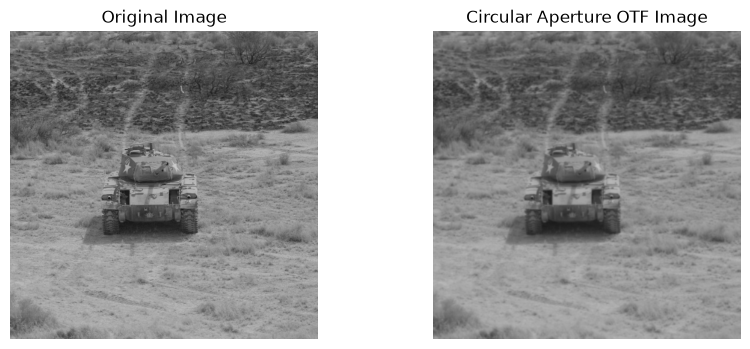

In [5]:
from nrtk.impls.perturb_image.optical.otf import CircularAperturePerturber

otf = CircularAperturePerturber(mtf_wavelengths=[0.5e-6, 0.6e-6], mtf_weights=[0.5, 0.5], D=0.003, eta=0.0)
circular_aperture_otf_image, _ = otf(image=image, img_gsd=img_gsd)
display_augmented_image(image, circular_aperture_otf_image, "Circular Aperture OTF Image")

(howto-optical-defocus)=
## Defocus Perturbation

The Defocus OTF simulates perturbations based on blur width. This is approximated as a Gaussian blur effect
quantified by variance in blur spot radii.

To simulate different levels of
defocus, you can adjust `w_x` and `w_y` parameters. `w_x` and `w_y` refer to the (Gaussian) blur spot radii in
the `x` and `y` axes respectively. A smaller radius indicates a more focused (centered) blur spot, whereas a
larger radius indicates a blur effect that is more spread out. You can adjust these parameters or use your own
image to visualize the perturbation and study the effect on image quality. 

```{seealso}
For parameter details, see the
[DefocusPerturber API](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.DefocusPerturber.rst>).

For operational context, intended uses, and limitations of this perturbation, see [Target Out of Focus](<project:/explanations/operational_risk_modules/defocus.rst>).
```

Below is some example code that initializes and applies a [`DefocusPerturber`](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.DefocusPerturber.rst>).

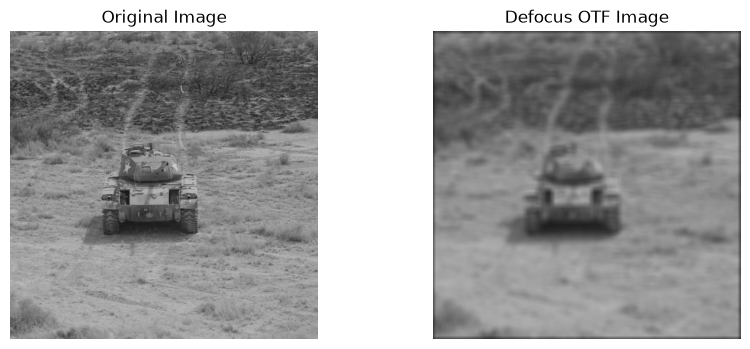

In [6]:
from nrtk.impls.perturb_image.optical.otf import DefocusPerturber

otf = DefocusPerturber(w_x=0.5, w_y=0.5)
defocus_otf_image, _ = otf(image=image, img_gsd=img_gsd)
display_augmented_image(image, defocus_otf_image, "Defocus OTF Image")

## Detector Perturbation

In imaging systems, a detector element (DEL) is a small, individual component that converts incident radiation
(e.g. X-rays, light, etc.) into an electrical signal, which is then used to create an image. These elements
are arranged in a matrix or array, forming the detector's overall (pixel) surface. The spatial resolution of a
detector system is directly related to the size of its detector elements or pixels. A detector with smaller
pixels can capture more detailed spatial information, while larger pixels cause blurring of fine details.

The Detector OTF simulates perturbations based on detector width; that is, blurring due to the spatial
integrating effects of the detector size. The width of a detector element along the x and y axes (`w_x` and
`w_y`) affects the spatial integration process. When photons from an image are detected, they are summed over
the area of the detector element. A wider element effectively integrates photons from a larger area,
which causes blurring of the output image.

To simulate different
detector sizes, you can adjust `w_x`, `w_y`, and `f` (focal length of detector) parameters. You can adjust
these parameters or use your own image to visualize the perturbation and study the effect on image quality.

```{seealso}
For parameter details, see the
[DetectorPerturber API](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.DetectorPerturber.rst>).

For related operational context on changes in optical resolution, see [Sensor Noise and Resolution](<project:/explanations/operational_risk_modules/sensor_noise_resolution.rst>).
```

Below is some example code that initializes and applies a [`DetectorPerturber`](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.DetectorPerturber.rst>).

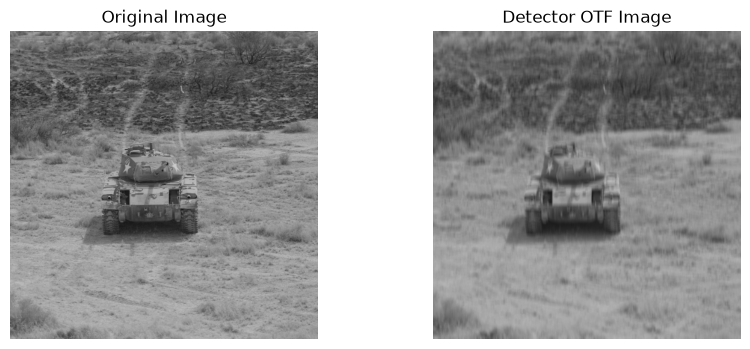

In [7]:
from nrtk.impls.perturb_image.optical.otf import DetectorPerturber

otf = DetectorPerturber(w_x=3e-6, w_y=20e-6, f=30e-3)
detector_otf_image, _ = otf(image=image, img_gsd=img_gsd)
display_augmented_image(image, detector_otf_image, "Detector OTF Image")

(howto-optical-jitter)=
## Jitter Perturbation

Jitter refers to small, rapid, unintended displacements of the imaging system (or its components) during
image acquisition. The Jitter OTF is modeled as a zero mean, Gaussian random process.

The higher the jitter, the narrower the Jitter OTF in frequency space. This suppresses high-frequency components,
leading to blurring of edges, loss of fine texture, and reduced contrast.

To simulate different levels
of jitter intensity, you can adjust `s_x` and `s_y` parameters, which represent the standard deviation of the
system's positional error due to motion in the `x` and `y` direction, respectively. You can adjust these parameters
or use your own image to visualize the perturbation and study the effect on image quality. 

```{seealso}
For parameter details, see the
[JitterPerturber API](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.JitterPerturber.rst>).

For operational context, intended uses, and limitations of this perturbation, see [High-Frequency Vibration](<project:/explanations/operational_risk_modules/high_frequency_vibration.rst>).
```

Below is some example code that initializes and applies a [`JitterPerturber`](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.JitterPerturber.rst>).

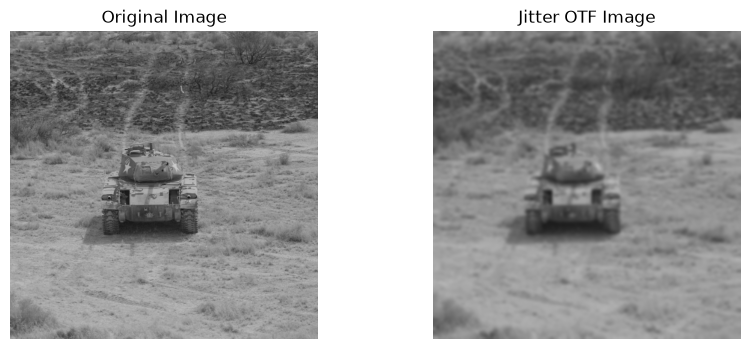

In [8]:
from nrtk.impls.perturb_image.optical.otf import JitterPerturber

otf = JitterPerturber(s_x=2e-4, s_y=2e-4)
jitter_otf_image, _ = otf(image=image, img_gsd=img_gsd)
display_augmented_image(image, jitter_otf_image, "Jitter OTF Image")

(howto-optical-turbulence)=
## Turbulence Aperture Perturbation

The Turbulence Aperture OTF degrades an image by simulating atmospheric turbulence and optical aperture effects.

To simulate different
atmospheric turbulence and optical aperture effects, you can adjust the following parameters:

- `mtf_wavelengths` - List of multispectral wavelength bands (m).
- `mtf_weights` - List of weights assigned to the corresponding wavelength bands to indicate relative
contribution to the overall signal (arbitrary value between 0.0 and 1.0).
- `altitude` - Sensor height above ground level (m).
- `slant_range` - Line-of-sight range between the aircraft and target, where the target is assumed to be on the
ground.
- `D` - Sensor's effective aperture diameter (m).
- `ha_wind_speed` - The high altitude windspeed (m/s).
- `cn2_at_1m` - The refractive index structure parameter "near the ground" (e.g. at h = 1 m); used to
calculate the turbulence profile. The default, 1.7e-14, is the Hufnagel-Valley (HV) 5/7 profile value.
- `int_time` - Integration time: The period during which a sensor accumulates incoming signals, such as light
or voltage, to measure a specific value (seconds).
- `n_tdi` - The number of time-delay integration stages (relevant only when TDI cameras are used; for CMOS
cameras, the value can be assumed to be 1.0).
- `aircraft_speed` - Apparent atmospheric velocity of the aircraft mounted with the sensor (m/s); this can
just be the windspeed at the sensor position if the sensor is stationary.

You can adjust these parameters or use your own image to visualize the perturbation and study the effect on image
quality. 

```{seealso}
For parameter details, see the
[TurbulenceAperturePerturber API](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.TurbulenceAperturePerturber.rst>).

For operational context, intended uses, and limitations of this perturbation, see [Atmospheric Turbulence](<project:/explanations/operational_risk_modules/atmospheric_turbulence.rst>).
```

Below is some example code that initializes and applies a [`TurbulenceAperturePerturber`](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.TurbulenceAperturePerturber.rst>).

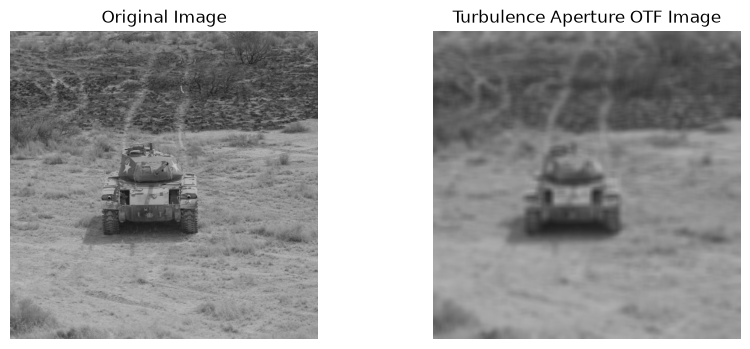

In [9]:
from nrtk.impls.perturb_image.optical.otf import TurbulenceAperturePerturber

otf = TurbulenceAperturePerturber(
    mtf_wavelengths=[0.50e-10, 0.66e-10],
    mtf_weights=[1.0, 1.0],
    altitude=250,
    slant_range=250,
    D=40e-3,
    ha_wind_speed=0,
    cn2_at_1m=1.7e-14,
    int_time=30e-3,
    n_tdi=1.0,
    aircraft_speed=0,
)
turbulence_aperture_otf_image, _ = otf(image=image, img_gsd=img_gsd)
display_augmented_image(image, turbulence_aperture_otf_image, "Turbulence Aperture OTF Image")

## Related T&E Workflows

```{seealso}
See these optical perturbers applied in end-to-end testing & evaluation workflows:

- [Visual Focus](<project:/examples/maite/visual_focus.ipynb>) — apply [`DefocusPerturber`](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.DefocusPerturber.rst>) to quantify model degradation from out-of-focus imagery.
- [Motion Jitter](<project:/examples/maite/motion_jitter.ipynb>) — simulate camera motion jitter with [`JitterPerturber`](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.JitterPerturber.rst>) and assess its impact on detection accuracy.
- [Atmospheric Turbulence](<project:/examples/maite/atmospheric_turbulence.ipynb>) — model atmospheric distortion with [`TurbulenceAperturePerturber`](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.otf.TurbulenceAperturePerturber.rst>) and measure its impact on image quality and inference.
- [Resolution & Noise](<project:/examples/maite/sensor_resolution_and_noise.ipynb>) — explore how camera-specific transformations via [`PybsmPerturber`](<project:/reference/api/_implementations/nrtk.impls.perturb_image.optical.PybsmPerturber.rst>) affect model predictions across sensor parameters.
```

## Related Guide: PyBSM Default Configuration

```{seealso}
For a complete walkthrough of setting up and customizing pyBSM sensor and scenario configurations using `load_default_config`, see the
[PyBSM Default Configuration](<project:/examples/pybsm_default_config.ipynb>) guide.
```

```{toctree}
:hidden:

/examples/pybsm_default_config
```